# Table: Bound slope analyses — all blocks, OL and MX

Extends the Panel C and Panel D analyses from Figure 3 to all 6 blocks for both
the OL (online / blocked SNR) and MX (mixed SNR) datasets.

Two analyses, each computed per participant × block:

### 1. Bound ~ DT &nbsp;&nbsp;(Figure 3 Panel C)
Linear regression of |bound| on DT (DT ≥ 2).  
Tests whether inferred bounds grow systematically with decision time.  
**Null**: median slope = 0.

### 2. Δbound ~ bound &nbsp;&nbsp;(Figure 3 Panel D)
Linear regression of Δ|bound|ₜ = |bound|ₜ − |bound|ₜ₋₁ on previous |bound|ₜ₋₁.  
Tests whether large bounds tend to revert toward the mean across consecutive trials.  
Slope = −1 → pure regression to mean; slope = 0 → no systematic trial-to-trial change.  
**Null**: median slope = −1.

---

**Table summary per block**: median [IQR] of per-participant values,
plus Wilcoxon signed-rank p-value (vs. stated null) for each analysis.

**Data**: Both datasets loaded with `combine_snr=False` to retain all 6 raw
block / SNR combinations. Good-trial filter: DT ≥ 2, trial ≥ 10, no wall hit,
no RT below the RT cutoff. Both analyses draw from this same DT ≥ 2 filter.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC

In [2]:
# combine_snr=False retains each block as a separate condition rather than
# pooling across SNR levels, giving one row per block in the table.
data_table_ol = get_data_table(task_type='OL', combine_snr=False)
data_table_mx = get_data_table(task_type='MX', combine_snr=False)

BLOCKS = sorted(data_table_ol['block_index'].dropna().unique().astype(int))
print('OL blocks:', BLOCKS)
print('MX blocks:', sorted(data_table_mx['block_index'].dropna().unique().astype(int)))

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 10: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h38.21.334.csv
 11: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h39.55.789.csv
 12: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h50.32.243.csv
 13: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.09.514.csv
 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.15.544.csv
 22: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.38.686.csv
 23: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h38.09.692.csv
 24: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h38.11.723.csv
 25: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h38.45.662.csv
 26: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h34.58.360.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h36.01.907.csv
 36: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 38: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h36.38.133.csv
 39: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h37.29.011.csv
 40: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h37.41.349.csv
 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h38.40.806.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

...

 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.27.732.csv
 36: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.41.720.csv
 37: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.47.690.csv
 38: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h14.12.270.csv
 39: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h19.47.420.csv
 40: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h21.56.825.csv
 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.07.354.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.12.482.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.49.710.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h14.23.140.csv
 49: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h15.49.644.csv
 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 51: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h18.34.289.csv
 52: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h18.42.215.csv
 53: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h18.52.475.csv
 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h49.58.399.csv


 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_19h25.58.493.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-12-06_12h13.32.209.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-12-06_15h08.34.504.csv


OL blocks: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MX blocks: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [3]:
def compute_slope_stats(data_table, blocks):
    """
    For each block compute per-subject statistics:
      slopes_c : |bound| ~ DT slopes  (Figure 3 Panel C, DT >= 2)
      slopes_d : Δ|bound| ~ |bound| slopes  (Figure 3 Panel D)

    Both analyses draw from the same base trial set (good-quality trials with a
    valid bound).  A subject is included if they have >= 5 valid data points,
    matching Figure03_boundSummary.ipynb's Panel C/D per-subject inclusion threshold.

    Returns a list of row-dicts (one per block) with median, IQR, Wilcoxon p,
    and participant count n.
    """
    subjects = np.sort(data_table['subject_index'].dropna().unique())
    good     = get_good_trial_array(data_table)
    rows = []

    for block in blocks:
        lg_base = (
            good &
            data_table['bound'].notna() &
            (data_table['block_index'] == block)
        )

        n_subj = sum(
            1 for subj in subjects
            if (lg_base & (data_table['subject_index'] == subj)).sum() >= 5
        )

        slopes_c = []
        slopes_d = []

        for subj in subjects:
            ls = lg_base & (data_table['subject_index'] == subj)

            # ── Analysis 1: |bound| ~ DT (DT >= 2) ──────────────────────────────
            # good/ls already ensures DT >= 2, so no separate DT filter is needed.
            sub_c = data_table[ls]
            if len(sub_c) >= 5:
                dts = sub_c['DT'].to_numpy(dtype=float)
                ab  = np.abs(sub_c['bound'].to_numpy(dtype=float))
                fin = np.isfinite(dts) & np.isfinite(ab)
                if fin.sum() >= 3:
                    try:
                        s, *_ = scipy.stats.linregress(dts[fin], ab[fin])
                        slopes_c.append(s)
                    except ValueError:
                        pass

            # ── Analysis 2: Δ|bound| ~ |bound| ──────────────────────────────────
            # Regress the trial-to-trial change against the PREVIOUS trial's
            # |bound| (not the current one) so that slope = -1 corresponds to
            # classical regression to the mean (matches PigeonSims.m / the
            # generic i.i.d.-noise demo in Figure03S04_sequentialAnalysis.ipynb).
            sub_d = data_table[ls].sort_values('trial_number')
            if len(sub_d) >= 5:
                ab    = np.abs(sub_d['bound'].to_numpy(dtype=float))
                prev  = ab[:-1]
                delta = ab[1:] - prev
                fin   = np.isfinite(prev) & np.isfinite(delta)
                if fin.sum() >= 3:
                    try:
                        s, *_ = scipy.stats.linregress(prev[fin], delta[fin])
                        slopes_d.append(s)
                    except ValueError:
                        pass

        def summarize(slopes, null=0.0):
            arr = np.asarray(slopes, dtype=float)
            if int(np.isfinite(arr).sum()) < 3:
                return dict(median=np.nan, q25=np.nan, q75=np.nan, p=np.nan)
            q25, med, q75 = np.percentile(arr, [25, 50, 75])
            try:
                _, p = scipy.stats.wilcoxon(arr - null)
            except ValueError:
                p = np.nan
            return dict(median=med, q25=q25, q75=q75, p=p)

        sc = summarize(slopes_c, null=0.0)
        sd = summarize(slopes_d, null=-1.0)
        rows.append(dict(
            block=block,
            n=n_subj,
            c_median=sc['median'], c_q25=sc['q25'], c_q75=sc['q75'], c_p=sc['p'],
            d_median=sd['median'], d_q25=sd['q25'], d_q75=sd['q75'], d_p=sd['p'],
        ))

    return rows

In [4]:
rows_ol = compute_slope_stats(data_table_ol, BLOCKS)
rows_mx = compute_slope_stats(data_table_mx, BLOCKS)

Cohort,Block (n),|bound|~DT median [IQR],p (H₀: 0),Δbound~bound median [IQR],p (H₀: −1)
1,1 (55),"0.002 [-0.009, 0.010]",0.621,"-0.969 [-1.077, -0.869]",0.284
1,2 (58),"-0.003 [-0.007, 0.003]",0.044,"-0.969 [-1.065, -0.837]",0.051
1,3 (52),"-0.002 [-0.010, 0.005]",0.181,"-0.972 [-1.063, -0.849]",0.131
1,4 (50),"0.006 [-0.015, 0.038]",0.137,"-0.995 [-1.121, -0.890]",0.688
1,5 (56),"-0.001 [-0.013, 0.017]",0.974,"-1.008 [-1.099, -0.889]",0.750
1,6 (47),"0.000 [-0.023, 0.021]",0.983,"-1.093 [-1.219, -0.855]",0.232
2,1 (60),"0.003 [-0.003, 0.013]",0.022,"-0.979 [-1.059, -0.912]",0.444
2,2 (59),"0.004 [-0.003, 0.010]",0.031,"-0.992 [-1.073, -0.882]",0.242
2,3 (53),"-0.003 [-0.010, 0.009]",0.562,"-1.022 [-1.106, -0.892]",0.933
2,4 (52),"0.009 [-0.005, 0.022]",0.015,"-1.040 [-1.147, -0.922]",0.101


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


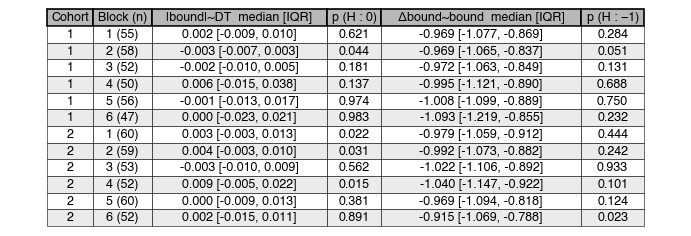

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Table_slopeAnalyses.pdf


In [5]:
def build_table(rows, dataset):
    def fmt_slope(med, q25, q75):
        if np.isnan(med):
            return 'NA'
        return f'{med:.3f} [{q25:.3f}, {q75:.3f}]'

    def fmt_p(p):
        if np.isnan(p):
            return 'NA'
        return f'{p:.3f}'

    records = []
    for r in rows:
        records.append({
            'Cohort':                     dataset,
            'Block (n)':                  f"{r['block']} ({r['n']})",
            '|bound|~DT  median [IQR]':   fmt_slope(r['c_median'], r['c_q25'], r['c_q75']),
            'p (H₀: 0)':                  fmt_p(r['c_p']),
            'Δbound~bound  median [IQR]': fmt_slope(r['d_median'], r['d_q25'], r['d_q75']),
            'p (H₀: −1)':                 fmt_p(r['d_p']),
        })
    return pd.DataFrame(records)


df_ol  = build_table(rows_ol, '1')
df_mx  = build_table(rows_mx, '2')
df_all = pd.concat([df_ol, df_mx], ignore_index=True)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)
display(df_all.style.hide())

# ── Save as PDF ────────────────────────────────────────────────────────────────
CM  = 1 / 2.54
FS  = 9
WID = 22   # cm

HEADER_BG = (0.72, 0.72, 0.72)   # darker gray for header row
ROW_GRAY  = (0.92, 0.92, 0.92)   # alternating light-gray data rows
ROW_WHITE = (1.00, 1.00, 1.00)   # alternating white data rows
THICK_LW  = 1.2                  # header border
THIN_LW   = 0.4                  # inner grid lines

plt.rcParams.update(FONT_RC)

fig, ax = plt.subplots(figsize=(WID * CM, 1))   # height adjusted by bbox_inches='tight'
ax.axis('off')

tbl = ax.table(
    cellText=df_all.values.tolist(),
    colLabels=list(df_all.columns),
    cellLoc='center',
    loc='center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(FS)
tbl.auto_set_column_width(col=list(range(len(df_all.columns))))

for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor(HEADER_BG)
        cell.set_linewidth(THICK_LW)
    else:
        cell.set_facecolor(ROW_GRAY if row % 2 == 0 else ROW_WHITE)
        cell.set_linewidth(THIN_LW)

out = FIGURES_DIR / 'Table_slopeAnalyses.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')